In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'tensorflow', 'keras', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'keras': 'keras==3.14.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'tensorflow' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'tensorflow.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Normalization Layers

When we trained LeNet in that section, the learning rate that suited
the MLP did not work. At a learning rate of 0.1 its validation accuracy
stayed at chance for the first few epochs and reached only 70--73% after ten;
we had to raise the rate to 2.0, twenty times larger, and train for 30 epochs
to reach about 89%. A network of five layers should not need such care. Why
does the right learning rate depend so strongly on the network, and can a
layer inside the network remove that dependence?

The cause is the scale of the signals inside the network. Each of LeNet's
four sigmoids multiplies the gradient by at most $1/4$ on the way back, so
the first layers receive much smaller gradients than the last, and no single
learning rate suits all of them. Deeper networks make the problem worse:
every layer changes the scale of the signals that enter the next one, and
these scales drift as the weights change during training.

*Batch normalization* [@Ioffe.Szegedy.2015] controls these scales
inside the network. Before the nonlinearity of a layer, it standardizes each
feature with the mean and the variance of the current minibatch, then applies
a learned scale and shift. A layer followed by batch normalization computes
the same output when its weights are multiplied by a constant, so its
gradient adapts to the size of its weights and one learning rate can serve
every layer. We will see that LeNet with batch normalization trains well at
the MLP's learning rate. Together with the residual connections of the next
section, batch normalization made networks with more than a hundred layers
trainable. Its statistics, however, couple the examples of a minibatch, which
fails when minibatches are small. The last part of this section introduces
layer and group normalization, which compute their statistics within each
example.

In [ ]:
import math
import numpy as np
import tensorflow as tf
from d2l import tensorflow as d2l

## Batch Normalization

### Standardizing over a Minibatch

Consider one feature computed by a fully connected layer, say the input to
the nonlinearity of one hidden unit, and a minibatch $\mathcal{B}$ of $m$
examples. The layer produces one value $x_i$ of this feature for each
example $i$. Batch normalization computes the mean and the variance of these
$m$ values,

$$\hat{\mu}_{\mathcal{B}} = \frac{1}{m} \sum_{i=1}^m x_i
\quad \textrm{and} \quad
\hat{\sigma}^2_{\mathcal{B}} = \frac{1}{m} \sum_{i=1}^m
(x_i - \hat{\mu}_{\mathcal{B}})^2,$$

and replaces each value by

$$
\textrm{BN}(x_i) = \gamma \, \frac{x_i - \hat{\mu}_{\mathcal{B}}}
{\sqrt{\hat{\sigma}^2_{\mathcal{B}} + \epsilon}} + \beta.
$$

The fraction standardizes the feature: over the minibatch it has mean 0 and
variance $\hat{\sigma}^2_{\mathcal{B}} / (\hat{\sigma}^2_{\mathcal{B}} +
\epsilon)$, just below 1. The small constant $\epsilon > 0$, typically
$10^{-5}$, prevents a division by zero when the feature takes the same value
on every example of the minibatch. A layer with several features normalizes
each of them separately, with its own mean and variance.

For example, the four values $(2, 4, 6, 8)$ have mean 5 and variance
$(9 + 1 + 1 + 9)/4 = 5$. Ignoring $\epsilon$, they are standardized to
$(x_i - 5)/\sqrt{5} \approx (-1.34, -0.45, 0.45, 1.34)$. The values
$(20, 40, 60, 80)$ and $(102, 104, 106, 108)$ are standardized to the same
four numbers: the standardization removes the scale and the offset of the
feature.

Mean 0 and variance 1 need not be what the next layer works best with. A
sigmoid, for instance, is nearly linear on inputs of unit variance. The
*scale* $\gamma$ and the *shift* $\beta$ in the equation restore
this freedom. They are parameters learned with the weights, one pair per
feature, initialized to $\gamma = 1$ and $\beta = 0$. With $\gamma =
\sqrt{\hat{\sigma}^2_{\mathcal{B}} + \epsilon}$ and $\beta =
\hat{\mu}_{\mathcal{B}}$ the layer would undo the standardization entirely, so
batch normalization does not restrict what a network can represent.

### Scale Invariance

Removing the scale of a feature changes how its weights learn. Let $x_i =
\mathbf{w}^\top \mathbf{h}_i + b$ be computed from the inputs
$\mathbf{h}_i$ of example $i$. Multiplying $\mathbf{w}$ and $b$ by a
constant $a > 0$ multiplies every $x_i$, their mean, and their standard
deviation by $a$, so, ignoring $\epsilon$,

$$\textrm{BN}(a \mathbf{w}^\top \mathbf{h}_i + a b) =
\textrm{BN}(\mathbf{w}^\top \mathbf{h}_i + b).$$

The loss therefore depends on the direction of the weights but not on their
length. Differentiating both sides with respect to $\mathbf{w}$ shows that
the gradient at $a \mathbf{w}$ is $1/a$ times the gradient at $\mathbf{w}$
[@Ioffe.Szegedy.2015]: small weights receive large gradients and large
weights small ones. The same holds for the signal itself. A feature that
barely varies over the minibatch, such as one computed from sigmoid outputs
that all lie near $1/2$, is divided by its small
$\hat{\sigma}_{\mathcal{B}}$ on the way forward, and its gradient is
multiplied by the same factor $1/\hat{\sigma}_{\mathcal{B}}$ on the way back. The learning rate no longer has to match the scale of each
layer, so one rate can serve all layers, and larger rates become safe.

### Fully Connected and Convolutional Layers

In a fully connected layer with weights $\mathbf{W}$, bias $\mathbf{b}$, and
activation function $\phi$, batch normalization goes between the affine map
and the nonlinearity, as in the original paper [@Ioffe.Szegedy.2015]:

$$\mathbf{h} = \phi(\textrm{BN}(\mathbf{W}\mathbf{x} + \mathbf{b})).$$

Each of the outputs of the affine map is one feature with its own statistics
and its own $\gamma_j$ and $\beta_j$. Other placements, such as after the
activation, are also in use.

A convolutional layer applies the same kernel at every position, and batch
normalization follows suit: it treats each output *channel* as one feature
and computes its mean and variance over the examples of the minibatch *and*
over all positions. With $m$ examples and an output of height $p$ and width
$q$, each channel's statistics average $m \cdot p \cdot q$ numbers. For the
first convolutional layer of LeNet, which produces six channels of $28
\times 28$, a minibatch of 128 images gives $128 \cdot 28 \cdot 28 =
100{,}352$ numbers per channel, against 128 per feature in a fully connected
layer. Each channel has a single $\gamma$ and $\beta$, so the normalized
layer still applies the same function at every position.

### Training and Prediction

At prediction time a model may see one image at a time, and its output for
an image should not depend on which other images happen to share its
minibatch. Batch normalization therefore uses two different statistics in
two modes. In *training mode* it normalizes with the statistics of the
current minibatch, as in the equation. It also keeps running
estimates $\hat{\mu}$ and $\hat{\sigma}^2$ of the mean and the variance,
starting from 0 and 1, and updates them after every minibatch,

$$
\hat{\mu} \leftarrow \rho \, \hat{\mu} + (1 - \rho) \,
\hat{\mu}_{\mathcal{B}} \quad \textrm{and} \quad
\hat{\sigma}^2 \leftarrow \rho \, \hat{\sigma}^2 + (1 - \rho) \,
\hat{\sigma}^2_{\mathcal{B}}.
$$

The *decay* $\rho$ sets the memory of these exponential moving averages: the
minibatch $k$ steps back contributes with weight $(1 - \rho)\rho^k$. With
$\rho = 0.9$ these weights halve about every seven steps, and the estimates
average over roughly the last $1/(1 - \rho) = 10$ minibatches, a small
fraction of the 469 minibatches of 128 images in one epoch of Fashion-MNIST.
In *prediction mode* the layer normalizes with the running estimates and
leaves them unchanged, so it computes a fixed affine function of each
feature. Dropout (that section) also has two modes: it zeroes units
during training and passes them through unchanged at prediction time.

Framework layers call $\rho$ or $1 - \rho$ the *momentum* of the layer, a name
unrelated to the momentum method of optimization. Throughout this chapter we
use $\rho = 0.9$ and $\epsilon = 10^{-5}$ and pass them explicitly where the
layer's defaults differ. A larger $\rho$ averages over more steps, during
which the weights keep changing, so early in training its estimates lag behind
the network that the training mode sees.

## Implementation from Scratch

The function `batch_norm` implements the equation and
the equation for both modes. For a fully connected layer it
averages over the examples; for a convolutional layer, over the examples and
the positions, one mean per channel.
<!-- d2l:prose id=batch-norm-md-3 fw=tensorflow, jax -->

Images are stored as (examples, height, width, channels), so the channel
axis is the last.

In [2]:
def batch_norm(X, gamma, beta, moving_mean, moving_var, eps, momentum,
               training):
    if not training:
        # Prediction mode: normalize with the running estimates
        X_hat = (X - moving_mean) / tf.sqrt(moving_var + eps)
    else:
        assert len(X.shape) in (2, 4)
        # Channels last: average over every axis except the last one
        axes = list(range(len(X.shape) - 1))
        mean = tf.reduce_mean(X, axes)
        var = tf.reduce_mean((X - mean) ** 2, axes)
        X_hat = (X - mean) / tf.sqrt(var + eps)
        # Update the running estimates in place; `momentum` is the decay rho
        moving_mean.assign(momentum * moving_mean + (1.0 - momentum) * mean)
        moving_var.assign(momentum * moving_var + (1.0 - momentum) * var)
    return gamma * X_hat + beta  # Scale and shift

The layer `BatchNorm` holds two kinds of state. The scale `gamma` and the
shift `beta` are parameters, updated by the optimizer. The running estimates
`moving_mean` and `moving_var` are not parameters: the optimizer must leave
them alone, but they belong to the model, which saves them and moves them to
the GPU with its parameters. Our layer is told the number of features and
the number of axes of its input; the framework layers infer both from the
first minibatch.

In [3]:
class BatchNorm(tf.keras.layers.Layer):
    def build(self, input_shape):
        shape = [input_shape[-1]]  # One entry per feature or channel
        # Scale and shift, learned, start at 1 and 0
        self.gamma = self.add_weight(name='gamma', shape=shape,
                                     initializer='ones')
        self.beta = self.add_weight(name='beta', shape=shape,
                                    initializer='zeros')
        # Running estimates, not learned, start at 0 and 1
        self.moving_mean = self.add_weight(name='moving_mean', shape=shape,
            initializer='zeros', trainable=False)
        self.moving_var = self.add_weight(name='moving_var', shape=shape,
            initializer='ones', trainable=False)

    def call(self, X, training=False):
        return batch_norm(X, self.gamma, self.beta, self.moving_mean,
                          self.moving_var, eps=1e-5, momentum=0.9,
                          training=training)

`add_weight(..., trainable=False)` creates variables that the layer saves
but the optimizer ignores. Keras passes `training=True` to `call` during
training steps.

To check the implementation, we apply our layer and the framework's batch
normalization layer, with $\rho = 0.9$ and $\epsilon = 10^{-5}$, to the same
minibatch of 128 six-channel $28 \times 28$ feature maps whose entries have
mean 2 and standard deviation 3. We print the largest per-channel mean and
the average per-channel variance of our output, its largest difference from
the framework's output, and our running means after this one step.

In [4]:
X = 2 + 3 * tf.random.normal((128, 28, 28, 6))
bn = BatchNorm()
bn_ref = tf.keras.layers.BatchNormalization(momentum=0.9, epsilon=1e-5)
Y, Y_ref = bn(X, training=True), bn_ref(X, training=True)
(float(tf.reduce_max(tf.abs(tf.reduce_mean(Y, axis=(0, 1, 2))))),
 float(tf.reduce_mean(tf.math.reduce_variance(Y, axis=(0, 1, 2)))),
 float(tf.reduce_max(tf.abs(Y - Y_ref))), bn.moving_mean.numpy())

(3.596045416998095e-08,
 0.9999988675117493,
 4.76837158203125e-07,
 array([0.20056832, 0.20095508, 0.20071502, 0.20042889, 0.20048666,
        0.20050357], dtype=float32))

Every channel of the output has mean 0 and variance 1 up to single-precision
roundoff, and our layer agrees with the framework's to within about $10^{-6}$. After
one step the running means have moved $1 - \rho$, a tenth of the way, from
their starting value 0 toward the minibatch means of about 2.


## LeNet with Batch Normalization

We now add batch normalization to LeNet, using the framework layers. The
network is the LeNet of that section: two $5 \times 5$ convolutional
layers with 6 and 16 channels, the first padded by 2, each followed by a
sigmoid and $2 \times 2$ average pooling, then fully connected layers with
120, 84, and 10 outputs, sigmoids between them. Its weights start from
Xavier initialization and its biases at zero, as in LeNet. `BNLeNet` inserts
a batch normalization layer after each of the four hidden layers, before its
sigmoid, and drops the biases of these layers: batch normalization subtracts
the mean of each feature, which removes any bias added before it, and its
shift $\beta$ takes over the role of the bias. Each of the
$6 + 16 + 120 + 84 = 226$ normalized features thus trades one bias for a
scale and a shift, 226 parameters on top of LeNet's 61,706.

In [5]:
class BNLeNet(d2l.Classifier):
    """LeNet with batch normalization before each hidden sigmoid."""
    def __init__(self, lr=0.1, num_steps=4690, num_classes=10):
        super().__init__()
        self.save_hyperparameters()
        layers = tf.keras.layers
        def bn():  # rho = 0.9 and epsilon = 1e-5
            return layers.BatchNormalization(momentum=0.9, epsilon=1e-5)
        self.net = tf.keras.models.Sequential([  # No biases before BN
            layers.Conv2D(6, kernel_size=5, padding='same', use_bias=False),
            bn(), layers.Activation('sigmoid'), layers.AvgPool2D(2, strides=2),
            layers.Conv2D(16, kernel_size=5, use_bias=False), bn(),
            layers.Activation('sigmoid'), layers.AvgPool2D(2, strides=2),
            layers.Flatten(),
            layers.Dense(120, use_bias=False), bn(),
            layers.Activation('sigmoid'),
            layers.Dense(84, use_bias=False), bn(),
            layers.Activation('sigmoid'),
            layers.Dense(num_classes)])

Keras' `BatchNormalization` defaults to `momentum=0.99` and
`epsilon=1e-3`, so we pass $\rho = 0.9$ and $\epsilon = 10^{-5}$. Its
`momentum` is $\rho$, as in our implementation. Xavier initialization
(`glorot_uniform`) and a zero bias for the output layer are the Keras
defaults.

Prediction mode raises one more issue. The running averages summarize the
statistics of the last ten or so minibatches, computed with weights that
have changed since. While the weights still move quickly, the running
averages describe a slightly different network from the one we evaluate.
With a constant learning rate of 0.1, the prediction-mode validation
accuracy of BN-LeNet drops by ten points or more in single epochs of some
runs, the last epoch included. We therefore let the
learning rate decay to zero during training: as the rate shrinks, the
weights stop moving and the running averages catch up with them. We use the
schedule with which we trained AlexNet (that section): a linear
warmup from zero to the peak rate over the first $t_\textrm{w}$ steps, then
the half-cosine the equation down to zero at the last step, as
computed by `d2l.cosine_warmup`.

`BNLeNet` steps the schedule after every minibatch, with a warmup of one
tenth of the `num_steps` steps of training. For a fair comparison, LeNet
gets the same schedule through a subclass.

In [6]:
@d2l.add_to_class(BNLeNet)
def configure_optimizers(self):
    schedule = lambda: self.lr * d2l.cosine_warmup(
        optim.iterations, self.num_steps, self.num_steps // 10)
    optim = tf.keras.optimizers.SGD(schedule)
    return optim

class CosineLeNet(d2l.LeNet):
    def __init__(self, lr=0.1, num_steps=4690, num_classes=10):
        super().__init__(lr, num_classes)
        self.num_steps = num_steps

    configure_optimizers = BNLeNet.configure_optimizers

We train LeNet and `BNLeNet` with identical settings, a base learning rate
of 0.1 (the MLP's), minibatches of 128 images, and 10 epochs of 469
minibatches, and keep the validation accuracy of each after every epoch.

In [7]:
data = d2l.FashionMNIST(batch_size=128)
num_steps = 10 * len(data.train_dataloader())
curves = {}
for model in (CosineLeNet(0.1, num_steps), BNLeNet(0.1, num_steps)):
    trainer = d2l.Trainer(max_epochs=10, num_gpus=1)
    trainer.board.display = False  # We plot the accuracies ourselves
    trainer.fit(model, data)
    curves[type(model).__name__] = trainer.history['val_acc']

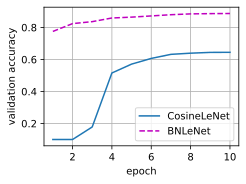

In [8]:
d2l.plot(list(range(1, 11)), list(curves.values()), 'epoch',
         'validation accuracy', legend=list(curves))

In [9]:
{name: round(acc[-1], 3) for name, acc in curves.items()}  # After 10 epochs

{'CosineLeNet': 0.645, 'BNLeNet': 0.887}

LeNet sits at chance, 10%, for the first two to five epochs, and after ten it
reaches about 60%, less in runs that stay at chance longer. With
batch normalization the same network is near 70% or above after the first
epoch and reaches about 88% after ten, close to the 88--90% that LeNet reaches
with twenty times the learning rate and three times the epochs. Its curve ends
without the dips of a constant learning rate. Batch normalization added 226
parameters and a few operations per activation; it changed the scale of every
layer's signal and gradient, not the capacity of the network.

Why batch normalization helps so much is less settled than what it computes.
@Ioffe.Szegedy.2015 attributed its effect to reducing *internal
covariate shift*, the change in the distribution of a layer's inputs as the
layers before it learn. @Santurkar.Tsipras.Ilyas.ea.2018 found that
batch normalization does not reduce this shift, and that training stays fast
even when noise is added after each normalization layer to create such
shift. They found instead that it makes the loss and its gradient change
more smoothly with the parameters. The scale invariance above is a third,
simpler part of the answer. The debate is a widely cited example of an
effect that was established long before its explanation
[@Lipton.Steinhardt.2018].

## Normalization without Batch Statistics

The output of batch normalization for one example depends on the other
examples in its minibatch. This coupling causes two problems. First, the
statistics are only as good as the minibatch is large. In a fully connected
layer, a minibatch of one example makes every standardized feature 0, since
each value equals its own mean; the layer then outputs $\beta$ whatever the
input. Object detection and semantic segmentation train on large images, so
memory often limits them to one or two images per GPU, where the statistics
are noisiest. Second, the network computes different functions in training
and in prediction mode. When the running estimates describe the data at
prediction time poorly, for instance after fine-tuning on data from another
domain, accuracy drops in a way that is hard to trace to a normalization
layer.

Both problems disappear when each example is normalized with statistics of
its own. the figure shows the options for a convolutional
layer, whose activations have an example axis $N$, a channel axis $C$, and
the spatial positions $H \cdot W$. They differ only in the set of numbers
that share one mean and one variance.

![Normalization methods for activations with examples $N$, channels $C$, and spatial positions $H\cdot W$. The shaded numbers share one mean and one variance. Batch normalization averages each channel over the minibatch and all positions; layer normalization averages each example over all channels and positions; group normalization over a group of channels and all positions; instance normalization over a single channel. The layer normalization of transformers and ConvNeXt averages over the channels at one position.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/arch-norm-axes.svg)

### Layer Normalization

*Layer normalization* [@Ba.Kiros.Hinton.2016] standardizes the
features of each example separately. For the $n$ features
$\mathbf{x} = (x_1, \ldots, x_n)$ of one example it computes

$$\textrm{LN}(\mathbf{x})_j = \gamma_j \, \frac{x_j - \hat{\mu}}
{\sqrt{\hat{\sigma}^2 + \epsilon}} + \beta_j
\quad \textrm{with} \quad
\hat{\mu} = \frac{1}{n} \sum_{j=1}^n x_j
\quad \textrm{and} \quad
\hat{\sigma}^2 = \frac{1}{n} \sum_{j=1}^n (x_j - \hat{\mu})^2.$$

This is the equation with the roles of examples and features
exchanged: the average runs over the features of one example instead of over
the examples of one feature, while the scale $\gamma_j$ and the shift
$\beta_j$ remain per feature. No other example enters, so layer normalization
computes the same function at every minibatch size and in both modes, and it
keeps no running estimates. Which features are averaged together depends on
the model. Transformers normalize the vector of each token, and the
convolutional network ConvNeXt (that section) likewise normalizes
the channel vector at each position, the last panel of
the figure.

### Group and Instance Normalization

For convolutional layers, *group normalization* [@wu2018groupnorm]
divides the $c$ channels into $G$ groups of $c/G$ channels and standardizes
each example separately over each group, that is, over $(c/G) \cdot p \cdot q$
numbers, followed by a scale and a shift per channel. With $G = 1$ it
normalizes each example over all channels and positions at once, the layer
normalization of the figure. With $G = c$ it normalizes every
channel of every example separately; this special case is called *instance
normalization*. Intermediate group counts, typically $G = 32$, give each
group enough numbers for stable statistics without forcing unrelated
channels to share them. We check on a minibatch of 32 examples with 16
channels and 4 groups that every (example, group) pair is standardized, and
that normalizing the first example alone gives the same output as
normalizing it within the minibatch.

In [10]:
X = tf.random.normal((32, 8, 8, 16))  # Channels last, as Keras expects
gn = tf.keras.layers.GroupNormalization(groups=4, epsilon=1e-5)
Y = gn(X)
# Collect each (example, group) pair's numbers
G = tf.reshape(tf.transpose(Y, (0, 3, 1, 2)), (32, 4, -1))
(tf.reduce_max(tf.abs(tf.reduce_mean(G, axis=2))),
 tf.reduce_mean(tf.math.reduce_variance(G, axis=2)),
 tf.reduce_max(tf.abs(gn(X[:1]) - Y[:1])))

(<tf.Tensor: shape=(), dtype=float32, numpy=2.421438694000244e-08>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.9999896883964539>,
 <tf.Tensor: shape=(), dtype=float32, numpy=5.960464477539063e-08>)

Each group has mean 0 and variance 1 up to roundoff, and the first example
is normalized the same way alone as within the minibatch. With large
minibatches batch normalization keeps a small edge: for a ResNet-50 trained
on ImageNet with 32 images per GPU, @wu2018groupnorm report a top-1
error of 23.6% with batch normalization and 24.1% with group normalization.
With 2 images per GPU the error of batch normalization rises to 34.7%, while
that of group normalization stays at 24.1%. Group normalization is therefore
common where minibatches are small, as in detection and segmentation. When
training runs on several GPUs, *synchronized* batch normalization is another
remedy: it computes the statistics over the global minibatch of all devices
instead of each device's share (that section).

### Normalizer-Free Networks

Normalization layers are not the only way to keep the scales of a deep
network under control. Normalizer-free networks (NFNets)
[@brock2021nfnet] train ResNet-style networks without any normalization
layer, to an ImageNet accuracy that was the best reported at the time for
a model trained on ImageNet alone. They standardize the weights of each
convolution instead of its outputs. Output channel $o$ of a convolution with
$c_\textrm{i}$ input channels and a $k \times k$ kernel has
$n_\textrm{in} = c_\textrm{i} k^2$ weights $\mathbf{w}_o$; with their mean
$\mu_o$ and standard deviation $\sigma_o$, the convolution uses
$$\hat{\mathbf{w}}_o = g_o \, \frac{\mathbf{w}_o - \mu_o}{\sigma_o \sqrt{n_\textrm{in}}}$$
with a learnable gain $g_o$. Before the gain, the standardized weights have
mean 0 and variance $1/n_\textrm{in}$ for any $\mathbf{w}_o$, so they keep
throughout training the scale that a careful initialization
(that section) sets only at the start; NFNets multiply them by a
further constant that depends on the activation function. NFNets also clip a
gradient whose norm is large relative to the norm of the weights it updates.
Without batch statistics, the network computes the same function in training
and at prediction time and its examples are independent.

## Summary

Batch normalization standardizes each feature of a layer, or each channel of
a convolutional layer, with the mean and the variance of the current
minibatch, then applies a learned scale and shift. The standardized layer is
invariant to the scale of its weights, so its gradient adapts to their size
and one learning rate suits every layer: LeNet with batch normalization
trains well at a learning rate twenty times smaller than LeNet needs without
it. At prediction time the layer uses running averages of the statistics,
which makes it the second layer, after dropout, that behaves differently in
training and prediction. Its dependence on the minibatch fails when
minibatches are small; layer and group normalization compute their
statistics within each example and avoid both the coupling and the two
modes. The next section combines batch normalization with residual
connections to train much deeper networks.

## Exercises

1. **Bias before batch norm.** `BNLeNet` builds its four normalized layers
   without a bias. Show from the equation that adding a bias
   $\mathbf{b}$ before the normalization changes neither the output in
   training mode nor the gradient with respect to the weights, and that the
   gradient with respect to $\mathbf{b}$ is zero. What happens to such a
   bias in prediction mode?
1. [code] **Learning-rate ceiling.** Train LeNet (that section) and
   `BNLeNet` for 10 epochs at learning rates 0.1, 0.3, 1, 3, and 10. Plot
   the final validation accuracy of both models against the learning rate
   on a logarithmic axis. Which range of learning rates does each model
   tolerate, and how does the scale invariance of batch normalization
   explain the difference?
1. [code] **Leave-one-out ablation.** Does every layer need batch
   normalization? `BNLeNet` normalizes the output of each of its four
   hidden layers. Remove batch normalization from one layer at a time and
   retrain. Report, as a table, the validation-accuracy cost of each
   removal, and identify the layer whose removal hurts most.
1. [code] **Running averages and recomputed statistics.** The decay
   $\rho$ in the equation sets how many minibatches the running
   estimates remember.
    1. After how many steps does the weight of a minibatch in the running
       mean fall below 1% of the weight of the newest minibatch, for
       $\rho = 0.9$ and for $\rho = 0.99$? Compare both with the 469
       steps of an epoch.
    1. Train `BNLeNet` for 10 epochs with a constant learning rate of 0.1,
       the `configure_optimizers` of `d2l.Classifier`, instead of the
       cosine schedule. After every epoch, evaluate a copy of the model
       twice: once in prediction mode as it is, and once after
       recomputing its statistics for the current weights. To recompute
       them, reset the running estimates and pass 100 training
       minibatches through the copy in training mode, without updating the
       weights, averaging the minibatch statistics with equal weights. Plot
       both validation curves, add the curve of this section's cosine
       schedule, and explain the differences.
    1. Repeat the second part with $\rho = 0.99$. Does a longer memory
       remove the difference? Why or why not?
1. [code] **Minibatch coupling.** The output of batch normalization for
   one example depends on the other examples in its minibatch. Train
   `BNLeNet` as in this section. Measure its validation accuracy in
   prediction mode, then in training mode with validation batches of 128
   images, and then in training mode with validation batches of one image.
   Measure in prediction mode first, since every training-mode forward
   pass updates the running estimates. Explain the three accuracies.
   If the layer refuses a training-mode minibatch of one example, explain
   why, and measure with minibatches of two instead.
1. [code] **Small-batch training.** ● Build a variant of `BNLeNet` that
   uses group normalization with two groups after each convolutional layer
   and layer normalization (that section)
   after each hidden fully connected layer, in place of batch
   normalization. Train `BNLeNet` and the variant for two epochs at batch
   size 4 and again at batch size 128, keeping the other hyperparameters
   of this section. Report the validation accuracy of all four runs. How
   does the accuracy of each network change when the batch size drops from
   128 to 4, and why?
1. [code] **Backward pass of batch norm.** ● The batch statistics in
   the equation depend on every element of the minibatch, so the
   backward pass is not elementwise.
    1. Derive, by hand, the gradient of a scalar loss with respect to each
       input of the batch-norm layer, working through the forward steps:
       mean, centering, variance, normalization, and the affine scale and
       shift.
    1. Implement your expression and verify it against the gradient
       computed by automatic differentiation.
    1. Show from your expression that the gradient with respect to the
       inputs sums to zero over the minibatch, and explain why.

    *Adapted from Simon Prince,
    [Understanding Deep Learning](https://udlbook.github.io/udlbook/),
    Problem 11.5.*
1. [extended] **Beyond mean and variance.** ●● Batch normalization
   standardizes each channel separately. For each of the following
   alternatives, describe how it would be applied at a layer and what it
   costs in computation, parameters, and estimation variance. Implement
   at least one of them in place of our `BatchNorm` in a copy of `BNLeNet`
   and compare its validation accuracy with that of batch normalization.
    1. The probability integral transform, which maps each channel through
       its empirical cumulative distribution function.
    1. Whitening with a full covariance estimate across the $c$ channels.
    1. Whitening with a structured covariance estimate, for example a
       block-diagonal or a low-rank-plus-diagonal matrix.

[Discussions](https://d2l.discourse.group/t/330)